# Demonstrasi Universal Meteorological Imputation Framework
Notebook ini mendemonstrasikan eksekusi end-to-end dari **Universal 2-Phase Hybrid Imputation Framework**:
1. Pemuatan data stasiun cuaca mikro AWS IoT Jerukagung (`id-03` & `id-05`).
2. Simulasi kehilangan data buatan (*Synthetic Gap Simulation*).
3. Rekonstruksi 2-Fase: **Fase 1 (Spline $\le 15$ min)** & **Fase 2 (Bi-LSTM / Spatial Transfer $> 15$ min)**.
4. Penegakan hukum fisik termodinamika (**Magnus-Tetens**) & **Savitzky-Golay Smoothing**.
5. Evaluasi metrik internasional: MAE, RMSE, $R^2$, NSE, dan KGE.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Hubungkan ke framework
sys.path.insert(0, os.path.abspath('.'))
from framework import MeteorologicalPreprocessor, SpatialTransferEngine, PhysicsPostProcessor, MeteorologicalEvaluator
from impute_pipeline import UniversalImputationPipeline

print("[OK] Framework modules imported successfully.")

[OK] Framework modules imported successfully.


## 1. Load Data Ground Truth Node 3 & Node 5

In [2]:
cache_dir = "../Analisis_Meteorologi/cache_data"
f_node3 = os.path.join(cache_dir, "id-03_raw.csv")
f_node5 = os.path.join(cache_dir, "id-05_raw.csv")

df3_raw = pd.read_csv(f_node3).tail(10000)
df5_raw = pd.read_csv(f_node5).tail(10000)

pipeline = UniversalImputationPipeline()
print(f"Loaded test segment: {len(df3_raw)} rows for Node 3 and {len(df5_raw)} rows for Node 5.")

[INFO] Successfully loaded Universal Bi-LSTM model.
Loaded test segment: 10000 rows for Node 3 and 10000 rows for Node 5.


## 2. Jalankan Rekonstruksi & Imputasi Otomatis

In [3]:
# Jalankan pipeline imputasi otomatis
df_clean = pipeline.impute_dataframe(df3_raw, node_id='id-03', df_companion=df5_raw)
print("Imputasi Selesai! Preview data bersih:")
df_clean[['temperature', 'humidity', 'pressure', 'dewpoint']].head()

[INFO] Applying Physics-Informed Post-Processing & Smoothing...
Imputasi Selesai! Preview data bersih:


,temperature,humidity,pressure,dewpoint
2026-08-16 15:34:00,30.84,75.50,1009.72,26.00
2026-08-16 15:35:00,30.79,75.62,1009.72,25.98
2026-08-16 15:36:00,30.74,75.74,1009.72,25.96
2026-08-16 15:37:00,30.69,75.86,1009.72,25.95
2026-08-16 15:38:00,30.64,75.99,1009.71,25.93


## 3. Visualisasi Hasil Imputasi Termodinamika

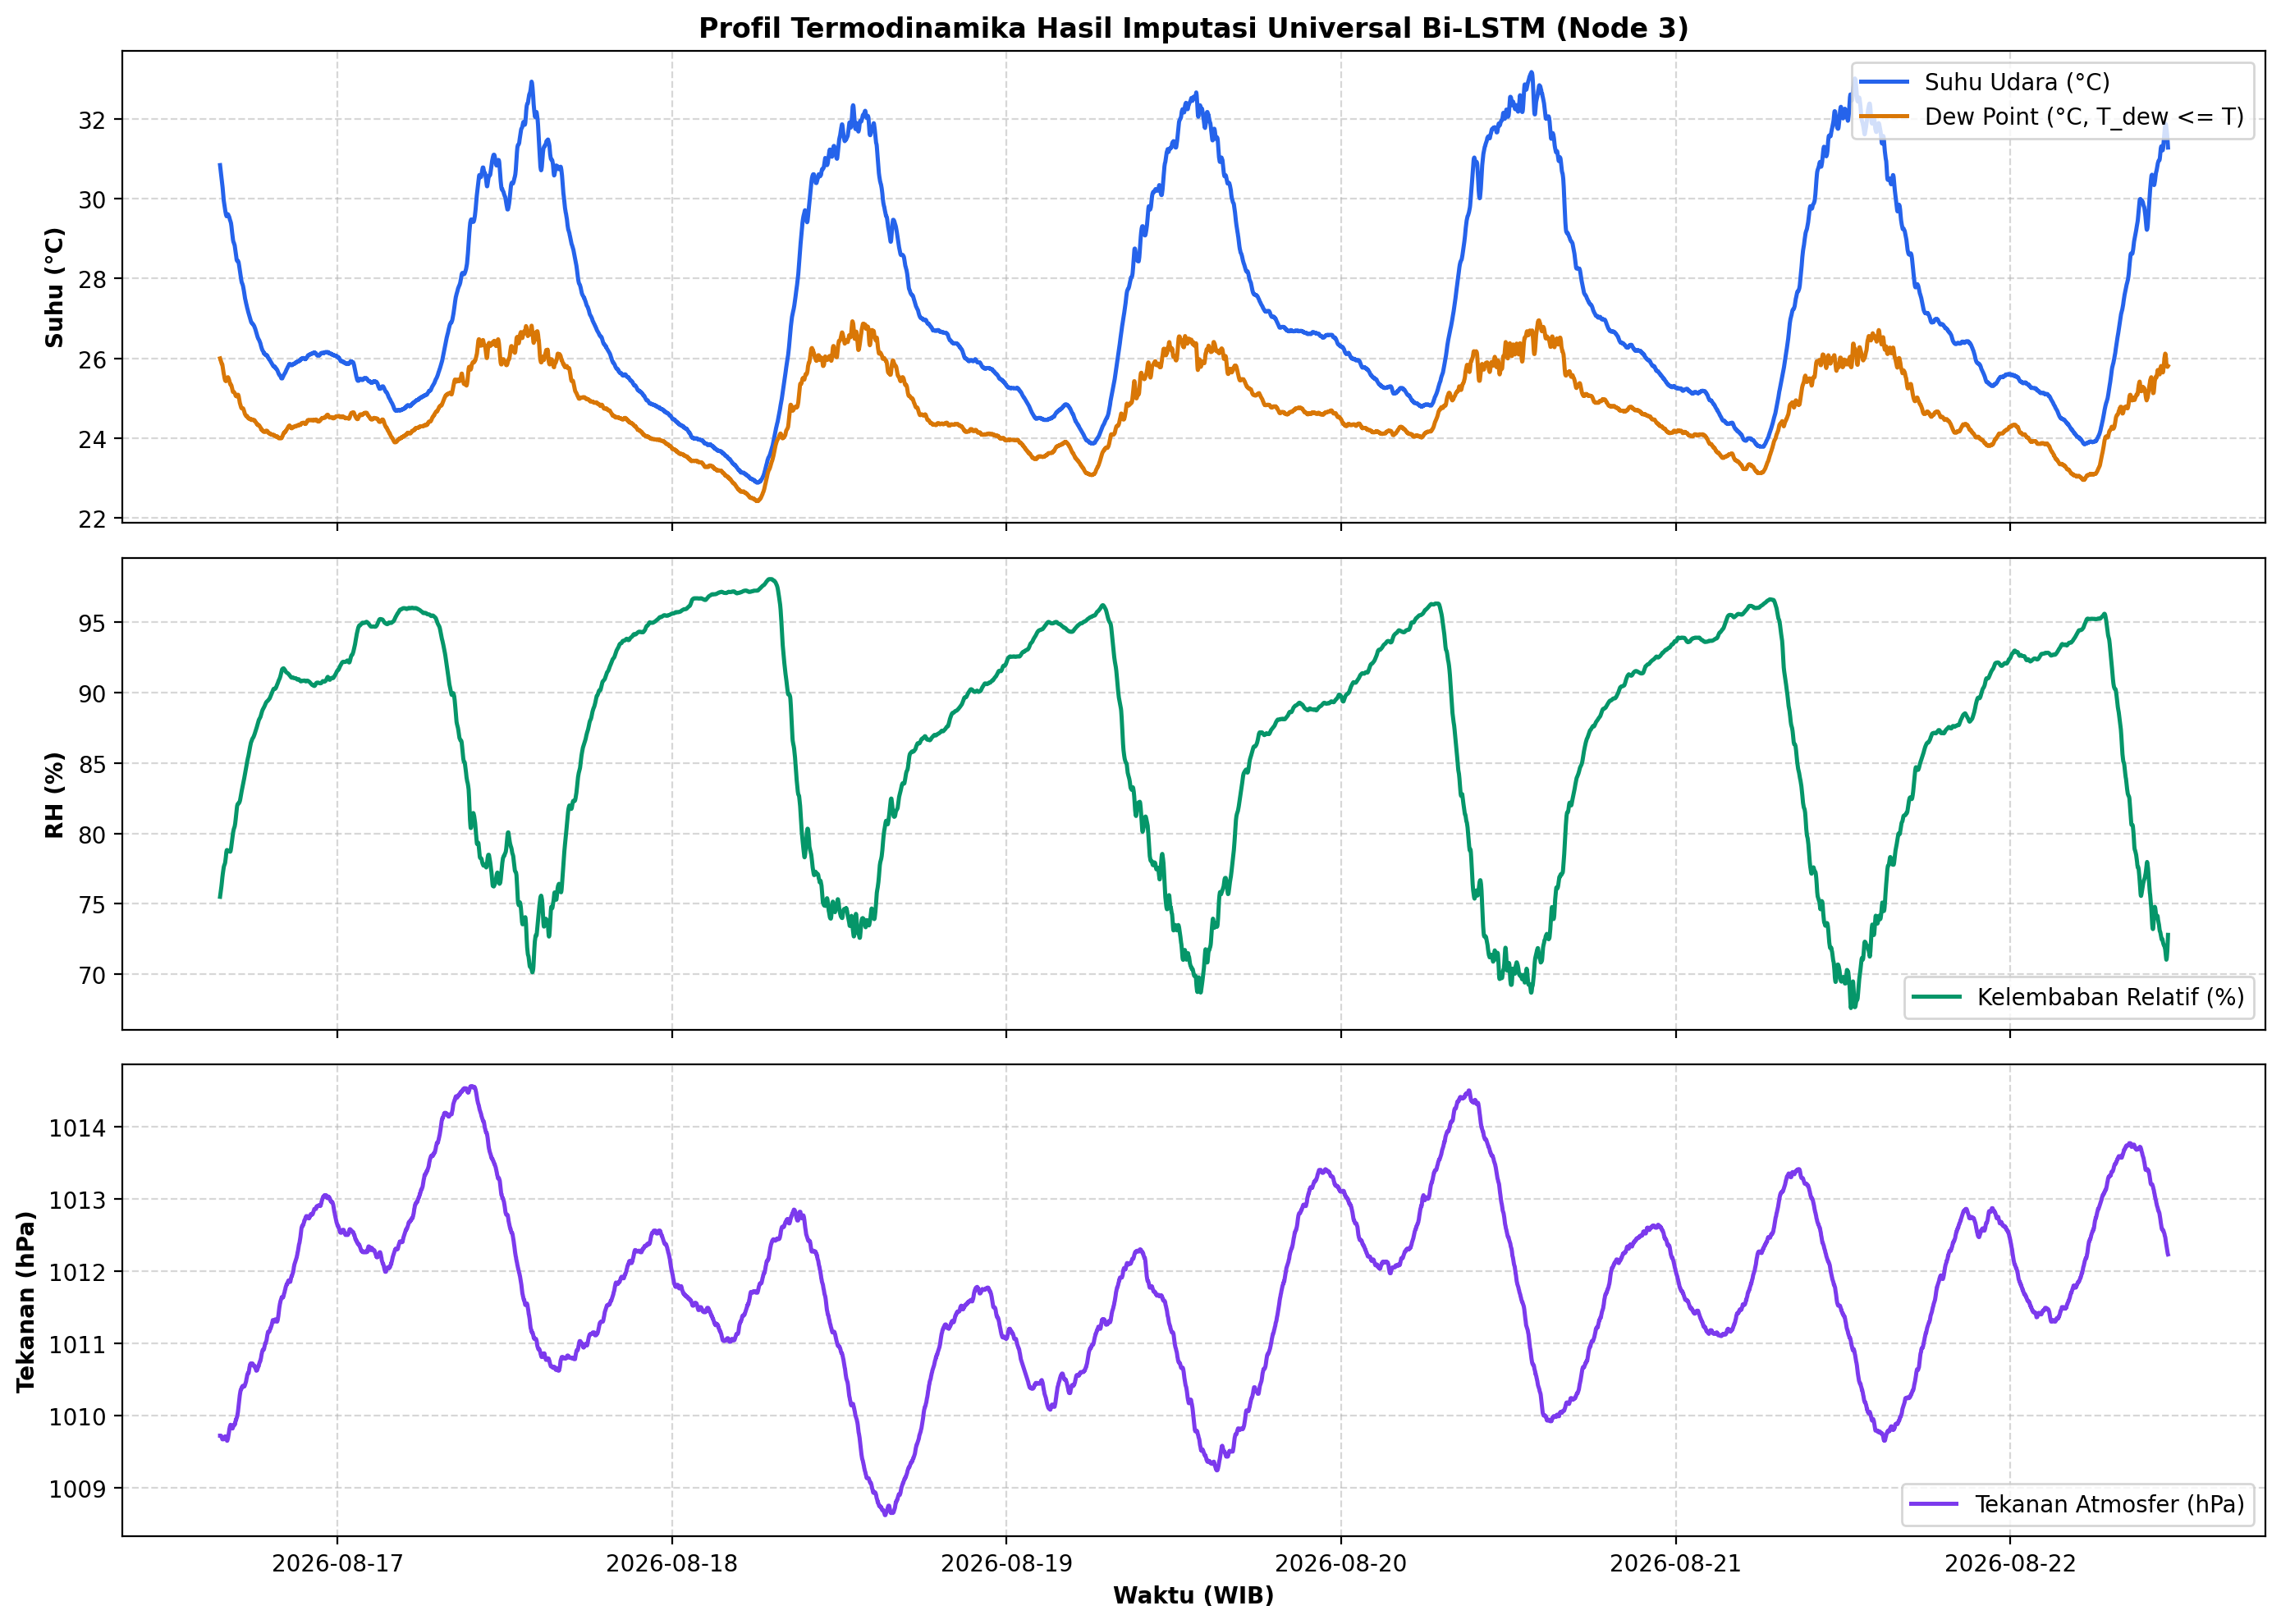

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, dpi=200)

# 1. Suhu & Dew Point
axes[0].plot(df_clean.index, df_clean['temperature'], label='Suhu Udara (°C)', color='#2563eb', linewidth=1.8)
axes[0].plot(df_clean.index, df_clean['dewpoint'], label='Dew Point (°C, T_dew <= T)', color='#d97706', linewidth=1.8)
axes[0].set_ylabel('Suhu (°C)', fontweight='bold')
axes[0].set_title('Profil Termodinamika Hasil Imputasi Universal Bi-LSTM (Node 3)', fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper right')

# 2. Kelembaban
axes[1].plot(df_clean.index, df_clean['humidity'], label='Kelembaban Relatif (%)', color='#059669', linewidth=1.8)
axes[1].set_ylabel('RH (%)', fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='lower right')

# 3. Tekanan Permukaan
axes[2].plot(df_clean.index, df_clean['pressure'], label='Tekanan Atmosfer (hPa)', color='#7c3aed', linewidth=1.8)
axes[2].set_ylabel('Tekanan (hPa)', fontweight='bold')
axes[2].set_xlabel('Waktu (WIB)', fontweight='bold')
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()